First five rows:
  school sex  age address famsize Pstatus  Medu  Fedu     Mjob      Fjob  ...  \
0     GP   F   18       U     GT3       A     4     4  at_home   teacher  ...   
1     GP   F   17       U     GT3       T     1     1  at_home     other  ...   
2     GP   F   15       U     LE3       T     1     1  at_home     other  ...   
3     GP   F   15       U     GT3       T     4     2   health  services  ...   
4     GP   F   16       U     GT3       T     3     3    other     other  ...   

  famrel freetime  goout  Dalc  Walc health absences  G1  G2  G3  
0      4        3      4     1     1      3        4   0  11  11  
1      5        3      3     1     1      3        2   9  11  11  
2      4        3      2     2     3      3        6  12  13  12  
3      3        2      2     1     1      5        0  14  14  14  
4      4        3      2     1     2      5        0  11  13  13  

[5 rows x 33 columns]

Dataset shape: (649, 33)

Columns:
['school', 'sex', 'age', 'address',

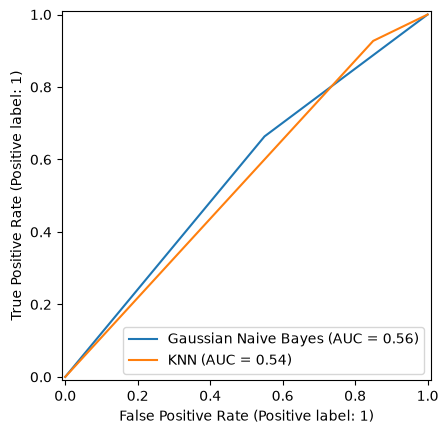

In [61]:

# ============================================================
# STUDENT PASS / FAIL PREDICTION - COMPLETE ML PIPELINE
# Dataset: UCI Student Performance (ID 320)
# Models: Gaussian Naive Bayes and KNN
# ============================================================

import pandas as pd

from ucimlrepo import fetch_ucirepo

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)


# ------------------------------------------------------------
# 1. LOAD THE DATASET
# ------------------------------------------------------------

student_data = fetch_ucirepo(id=320)

# Access the original dataset
df = student_data.data.original.copy()

print("First five rows:")
print(df.head())

print("\nDataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

print("\nMissing values:")
print(df.isnull().sum())


# ------------------------------------------------------------
# 2. CREATE THE TARGET: PASS OR FAIL
# ------------------------------------------------------------

# G3 is the final grade, normally on a 0-20 scale.
# Grade >= 10 means PASS; below 10 means FAIL.

if "G3" not in df.columns:
    raise ValueError("Expected final-grade column G3 was not found.")

y = (df["G3"] >= 10).astype(int)

# Remove grades from the input features.
# G1 and G2 are excluded to avoid using earlier grades
# as shortcuts when predicting from background information.
X = df.drop(columns=["G1", "G2", "G3"], errors="ignore")

print("\nTarget distribution:")
print(y.map({0: "Fail", 1: "Pass"}).value_counts())

print("\nFeature shape:", X.shape)


# ------------------------------------------------------------
# 3. IDENTIFY NUMERICAL AND CATEGORICAL FEATURES
# ------------------------------------------------------------

numeric_features = X.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X.select_dtypes(
    exclude=["number"]
).columns.tolist()

print("\nNumerical features:", numeric_features)
print("\nCategorical features:", categorical_features)


# ------------------------------------------------------------
# 4. SPLIT INTO TRAINING AND TEST DATA
# ------------------------------------------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTraining samples:", len(X_train))
print("Testing samples:", len(X_test))


# ------------------------------------------------------------
# 5. PREPROCESS THE FEATURES
# ------------------------------------------------------------

# Numerical columns:
# Fill missing values with the median, then scale.

numeric_pipeline = make_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler()
)

# Categorical columns:
# Fill missing values with the most frequent category,
# then convert categories into numeric indicator columns.

pipeline_2 = make_pipeline(
    SimpleImputer(strategy="most_frequent"),
    OneHotEncoder(sparse_output=False)
)

# Apply the correct preprocessing to each column type.

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", pipeline_2, categorical_features)
])


# ------------------------------------------------------------
# 6. DEFINE THE TWO CLASSIFICATION MODELS
# ------------------------------------------------------------

models = {
    "Gaussian Naive Bayes": make_pipeline(
        preprocessor,
        GaussianNB()
    ),

    "KNN": make_pipeline(
        preprocessor,
        KNeighborsClassifier(n_neighbors=5)
    )
}


# ------------------------------------------------------------
# 7. TRAIN, PREDICT AND EVALUATE
# ------------------------------------------------------------

results = []
ax = plt.gca()
for name, model in models.items():

    # Train the complete pipeline on training data
    model.fit(X_train, y_train)

    # Predict the classes of unseen test samples
    y_pred = model.predict(X_test)

    # Calculate evaluation metrics
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(
        y_test, y_pred, zero_division=0
    )
    recall = recall_score(
        y_test, y_pred, zero_division=0
    )
    f1 = f1_score(
        y_test, y_pred, zero_division=0
    )
    cm = confusion_matrix(
        y_test, y_pred, labels=[0, 1]
    )

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-score": f1
    })

    print("\n" + "=" * 50)
    print("MODEL:", name)
    print("=" * 50)

    print(f"Accuracy : {accuracy:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall   : {recall:.4f}")
    print(f"F1-score : {f1:.4f}")

    print("\nConfusion Matrix:")
    print(cm)

    print("\nClassification Report:")
    print(classification_report(
        y_test,
        y_pred,
        labels=[0, 1],
        target_names=["Fail", "Pass"],
        zero_division=0
    ))
    RocCurveDisplay.from_predictions(
        y_true=y_test, 
        y_score=y_pred, 
        name=name, 
        ax=ax
    )

# ------------------------------------------------------------
# 8. COMPARE BOTH MODELS
# ------------------------------------------------------------

results_df = pd.DataFrame(results)

print("\n\nFINAL MODEL COMPARISON")
print(results_df.to_string(index=False))

best_model = results_df.loc[
    results_df["F1-score"].idxmax()
]

print("\nBest model by F1-score:", best_model["Model"])
print("Best F1-score:", round(best_model["F1-score"], 4))


